# Criteo Sponsored Search — Chronological baseline (500,000 rows)

**Corrected:** `SAMPLE_ROWS = 500_000` is a Python integer; `500,000` would be a tuple and cause `TypeError`. Saved results from the prior 150,000-row run were cleared. Run all cells to obtain fresh 500,000-row results.

Self-contained notebook supporting headerless TSV and headered CSV/TSV Criteo files. Set `DATA_PATH` to your local file. Do not publish raw click data. Chronological analysis is retrospective; a split alone does not prove historical label availability.


In [1]:
from pathlib import Path
import csv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# CHANGE THIS to your real input file. Relative paths are relative to the notebook's working directory.
DATA_PATH = Path("../data/CriteoSearchData")
SAMPLE_ROWS = 500_000    # Sampling cap. If the file has <= this many rows, retain all.
CHUNK_SIZE = 50_000
RANDOM_SEED = 530

CRITEO_COLUMNS = [
    "Sale", "SalesAmountInEuro", "time_delay_for_conversion", "click_timestamp",
    "nb_clicks_1week", "product_price", "product_age_group", "device_type",
    "audience_id", "product_gender", "product_brand", "product_category1",
    "product_category2", "product_category3", "product_category4",
    "product_category5", "product_category6", "product_category7",
    "product_country", "product_id", "product_title", "partner_id", "user_id",
]
OUTCOME_DERIVED = ["SalesAmountInEuro", "time_delay_for_conversion"]

print("Dataset path:", DATA_PATH.resolve())
print("Exists:", DATA_PATH.is_file())
assert DATA_PATH.is_file(), "Set DATA_PATH to the actual local Criteo dataset file."

Dataset path: /Users/kranthikiranreddy/Downloads/criteo-conversion-research/data/CriteoSearchData
Exists: True


## Load a reproducible sample
Use the repaired EDA loader: infer format from file content, preserve all 23 fields (including titles with spaces), and retain rows by uniform random priorities across the full source.

In [2]:
def detect_file_format(path):
    """Return (separator, header_present). Refuse ambiguous or non-Criteo formats."""
    with open(path, "r", encoding="utf-8-sig", errors="replace") as handle:
        first = handle.readline().rstrip("\r\n")
    if not first:
        raise ValueError("Dataset file is empty.")
    # Count separators so a product-title field containing spaces stays a single column.
    delimiter = "\t" if first.count("\t") >= first.count(",") else ","
    fields = next(csv.reader([first], delimiter=delimiter))
    if len(fields) != 23:
        raise ValueError(f"Expected 23 fields, found {len(fields)}; check DATA_PATH and delimiter.")
    header_present = fields[0].strip().lower() == "sale"
    if header_present:
        if [v.strip() for v in fields] != CRITEO_COLUMNS:
            raise ValueError("Detected header, but names/order do not match the expected Criteo schema.")
    else:
        if fields[0].strip() not in {"0", "1"}:
            raise ValueError("First column is not Sale=0/1. Check that this is Criteo click data.")
        try:
            int(fields[3])
        except ValueError as exc:
            raise ValueError("Fourth column is not a Unix click timestamp.") from exc
    return delimiter, header_present


def load_criteo_sample(path, sample_rows=500_000, chunk_size=50_000, seed=530):
    """Read headerless/headered Criteo; uniform bounded random sample of all source rows."""
    if not isinstance(sample_rows, (int, np.integer)) or not isinstance(chunk_size, (int, np.integer)):
        raise TypeError("sample_rows and chunk_size must be integers (use 500_000, not 500,000).")
    if sample_rows < 1 or chunk_size < 1:
        raise ValueError("sample_rows and chunk_size must be positive")
    delimiter, has_header = detect_file_format(path)
    reader_kwargs = dict(sep=delimiter, header=0 if has_header else None,
                         chunksize=chunk_size, low_memory=False, dtype=str, encoding="utf-8-sig")
    if not has_header:
        reader_kwargs["names"] = CRITEO_COLUMNS
    rng = np.random.default_rng(seed)
    sample = pd.DataFrame()
    keys = np.empty(0, dtype=np.float64)
    scanned = 0
    for chunk in pd.read_csv(path, **reader_kwargs):
        chunk.columns = chunk.columns.astype(str).str.strip()
        if chunk.columns.tolist() != CRITEO_COLUMNS:
            raise ValueError(f"Unexpected columns: {chunk.columns.tolist()}")
        scanned += len(chunk)
        new_keys = rng.random(len(chunk))
        candidates = pd.concat((sample, chunk), ignore_index=True)
        candidate_keys = np.concatenate((keys, new_keys))
        if len(candidates) > sample_rows:
            idx = np.argpartition(candidate_keys, sample_rows - 1)[:sample_rows]
            sample = candidates.iloc[idx].reset_index(drop=True)
            keys = candidate_keys[idx]
        else:
            sample = candidates
            keys = candidate_keys
    if scanned == 0:
        raise ValueError("No data rows found")
    sample["Sale"] = pd.to_numeric(sample["Sale"], errors="raise")
    sample["click_timestamp"] = pd.to_numeric(sample["click_timestamp"], errors="raise")
    if not sample["Sale"].isin((0, 1)).all():
        raise ValueError("Sale must be 0 or 1 for every sampled row")
    return sample, scanned, delimiter, has_header

df, scanned_rows, delimiter, had_header = load_criteo_sample(
    DATA_PATH, sample_rows=SAMPLE_ROWS, chunk_size=CHUNK_SIZE, seed=RANDOM_SEED
)
print(f"Separator: {repr(delimiter)} | Header present: {had_header}")
print(f"Scanned: {scanned_rows:,} | Retained: {len(df):,} | Columns: {df.shape[1]}")
print("First six columns:", df.columns[:6].tolist())
assert df.shape[1] == 23 and {"Sale", "click_timestamp"}.issubset(df.columns)
display(df.dtypes.rename("dtype").to_frame())

Separator: '\t' | Header present: False
Scanned: 15,995,634 | Retained: 500,000 | Columns: 23
First six columns: ['Sale', 'SalesAmountInEuro', 'time_delay_for_conversion', 'click_timestamp', 'nb_clicks_1week', 'product_price']


,dtype
Sale,int64
SalesAmountInEuro,object
time_delay_for_conversion,object
click_timestamp,int64
nb_clicks_1week,object
product_price,object
product_age_group,object
device_type,object
audience_id,object
product_gender,object


## Chronological train, validation and test partitions
Discard invalid/nonpositive Unix-second timestamps with an explicit count. Choose approximately 60/20/20 boundaries by row count, keeping tied timestamps in the same partition. Fail clearly if there are too few distinct times or training has only one class.

`LABEL_GAP_DAYS=0` is the default retrospective baseline. An optional 30-day gap removes training/validation clicks immediately preceding the next partition; it can exhaust a short dataset and does not prove historical label availability. Choose this setting before examining holdout results.

In [3]:
LABEL_GAP_DAYS = 0
if not np.isfinite(LABEL_GAP_DAYS) or LABEL_GAP_DAYS < 0:
    raise ValueError("LABEL_GAP_DAYS must be finite and nonnegative")
ts = pd.to_numeric(df["click_timestamp"], errors="coerce")
click_time = pd.to_datetime(ts.where(ts.gt(0)), unit="s", utc=True, errors="coerce")
keep = click_time.notna()
print("Dropped invalid timestamps:", int((~keep).sum()))
ordered = df.loc[keep].assign(_click_time=click_time[keep]).sort_values("_click_time", kind="stable")
if len(ordered) < 5:
    raise ValueError("Not enough timestamp-valid rows for three partitions")
n = len(ordered)
valid_start = ordered["_click_time"].iloc[int(n * .6)]
test_start = ordered["_click_time"].iloc[int(n * .8)]
gap = pd.Timedelta(days=LABEL_GAP_DAYS)
train = ordered.loc[ordered._click_time < valid_start - gap].copy()
valid = ordered.loc[(ordered._click_time >= valid_start) & (ordered._click_time < test_start - gap)].copy()
test = ordered.loc[ordered._click_time >= test_start].copy()
if any(part.empty for part in (train, valid, test)):
    raise ValueError("Empty chronological partition: need more distinct timestamps/time coverage or a smaller gap")
assert train._click_time.max() < valid._click_time.min()
assert valid._click_time.max() < test._click_time.min()
if train["Sale"].nunique() != 2:
    raise ValueError("Training requires both Sale classes; increase sample size or review time coverage")
print("Rows excluded by gap:", len(ordered) - len(train) - len(valid) - len(test))
display(pd.DataFrame([
    {"split": name, "rows": len(part), "first_utc": part._click_time.min(),
     "last_utc": part._click_time.max(), "prevalence": part.Sale.mean()}
    for name, part in [("train", train), ("validation", valid), ("test", test)]
]))

Dropped invalid timestamps: 0
Rows excluded by gap: 0


,split,rows,first_utc,last_utc,prevalence
0,train,300000,2020-08-03 07:25:18+00:00,2020-09-29 22:50:32+00:00,0.113607
1,validation,100000,2020-09-29 22:50:47+00:00,2020-10-16 19:04:50+00:00,0.102740
2,test,100000,2020-10-16 19:04:54+00:00,2020-11-02 07:24:28+00:00,0.099080


## Conservative click-time candidate features
Exclude the target, both post-outcome fields, the raw timestamp and high-cardinality identifiers (`user_id`, `product_id`, `product_title`, `audience_id`, `partner_id`). Remaining attributes still require a source-specific availability audit. Parse price and click count as numeric, treating `-1` as missing. Treat hashed categories as strings, including numeric-looking values. Imputation, scaling and category grouping are fitted on training rows only.

In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, roc_auc_score, log_loss,
                             brier_score_loss, PrecisionRecallDisplay)
from sklearn.calibration import CalibrationDisplay

excluded = {"Sale", *OUTCOME_DERIVED, "click_timestamp", "_click_time",
            "user_id", "product_id", "product_title", "audience_id", "partner_id"}
feature_names = [c for c in CRITEO_COLUMNS if c not in excluded]
numeric_names = ["product_price", "nb_clicks_1week"]
cat_names = [c for c in feature_names if c not in numeric_names]

def make_features(part):
    X = part[feature_names].copy()
    for col in numeric_names:
        values = pd.to_numeric(X[col], errors="coerce")
        X[col] = values.mask(values.eq(-1) | ~np.isfinite(values))
    for col in cat_names:
        values = X[col].astype("string").str.strip()
        X[col] = values.mask(values.isin(["-1", "-1.0", ""])).fillna("__MISSING__").astype(str)
    return X

X_train, X_valid, X_test = [make_features(part) for part in (train, valid, test)]
y_train, y_valid, y_test = [part.Sale.astype(int).to_numpy() for part in (train, valid, test)]
assert not excluded.intersection(X_train.columns)
print("Numeric:", numeric_names, "Categorical:", cat_names)
preprocess = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median", keep_empty_features=True)),
                      ("scale", StandardScaler())]), numeric_names),
    ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=20), cat_names),
], sparse_threshold=1.0)
model = Pipeline([("preprocess", preprocess),
                  ("clf", LogisticRegression(max_iter=500, solver="liblinear", random_state=RANDOM_SEED))])
model.fit(X_train, y_train)

def score_predictions(y, probabilities):
    both_classes = len(np.unique(y)) == 2
    return {"AP": average_precision_score(y, probabilities) if np.any(y == 1) else np.nan,
            "ROC_AUC": roc_auc_score(y, probabilities) if both_classes else np.nan,
            "Log_loss": log_loss(y, probabilities, labels=[0, 1]),
            "Brier": brier_score_loss(y, probabilities),
            "prevalence": float(y.mean()), "rows": len(y)}

p_valid = model.predict_proba(X_valid)[:, 1]
display(pd.DataFrame([score_predictions(y_valid, p_valid)], index=["validation logistic"]))
print("AP is average precision, not trapezoidal PR area. Undefined metrics are NaN.")

Numeric: ['product_price', 'nb_clicks_1week'] Categorical: ['product_age_group', 'device_type', 'product_gender', 'product_brand', 'product_category1', 'product_category2', 'product_category3', 'product_category4', 'product_category5', 'product_category6', 'product_category7', 'product_country']


,AP,ROC_AUC,Log_loss,Brier,prevalence,rows
validation logistic,0.954486,0.98748,0.050974,0.011377,0.10274,100000


AP is average precision, not trapezoidal PR area. Undefined metrics are NaN.


## Final holdout report
Freeze feature choices and model settings using validation before running this cell. Compare logistic regression with a constant probability learned from **training prevalence**. Do not tune against test results. A one-class holdout has undefined ROC AUC; a holdout without positives also has undefined AP.

,AP,ROC_AUC,Log_loss,Brier,prevalence,rows
constant,0.099080,0.500000,0.324146,0.089474,0.09908,100000.0
logistic,0.955332,0.988069,0.048785,0.010779,0.09908,100000.0


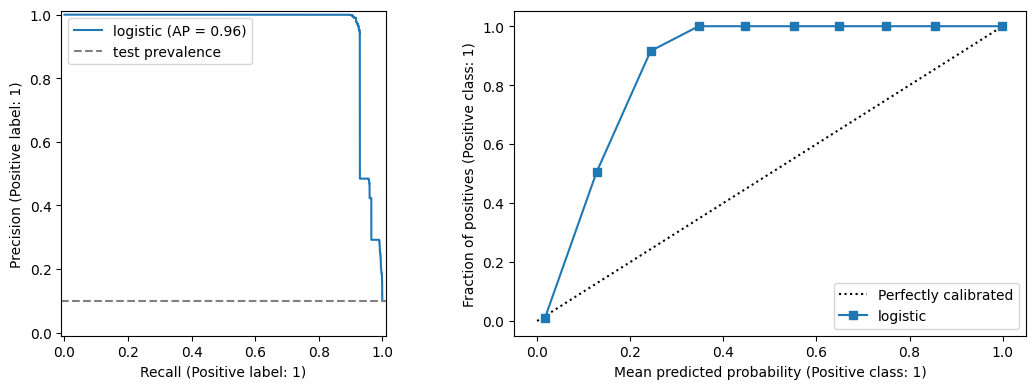

{'python': '3.9.6', 'pandas': '2.3.3', 'numpy': '2.0.2', 'sklearn': '1.6.1', 'seed': 530, 'sample_rows': 500000, 'scanned_rows': 15995634, 'gap_days': 0}


In [5]:
p_test = model.predict_proba(X_test)[:, 1]
p_const = np.full(len(y_test), y_train.mean())
results = pd.DataFrame({name: score_predictions(y_test, pred)
                        for name, pred in [("constant", p_const), ("logistic", p_test)]}).T
display(results)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
if np.any(y_test == 1):
    PrecisionRecallDisplay.from_predictions(y_test, p_test, ax=axes[0], name="logistic")
    axes[0].axhline(y_test.mean(), linestyle="--", color="gray", label="test prevalence")
    axes[0].legend()
else:
    axes[0].text(.5, .5, "PR curve undefined: no positive test labels", ha="center", wrap=True)
CalibrationDisplay.from_predictions(y_test, p_test, n_bins=10, ax=axes[1], name="logistic")
plt.tight_layout()
plt.show()
import platform, sklearn
print({"python": platform.python_version(), "pandas": pd.__version__,
       "numpy": np.__version__, "sklearn": sklearn.__version__, "seed": RANDOM_SEED,
       "sample_rows": SAMPLE_ROWS, "scanned_rows": scanned_rows, "gap_days": LABEL_GAP_DAYS})

## Interpretation and follow-up
Report actual metrics, split dates, prevalence, excluded timestamps, sampling settings and library versions after local execution. No empirical performance is asserted in this unexecuted notebook.

- The uniform click sample followed by sorting is a within-sample temporal evaluation, not a full-population deployment replay.
- Confirm the attribution horizon and evaluate a label-maturity gap separately; observed final outcomes do not reveal when each label became available.
- Compare random versus chronological splitting with features and algorithm held fixed, and investigate repeated identifiers and attribute availability.
- Use average precision, calibration, log loss and Brier together; add time-block uncertainty in later experiments.
- Keep raw records and row-level samples local. This notebook displays aggregates only.